# Crowd Avoidance · Hands-on vs. observing

Compare movement and proximity in two Compact Crowd Avoidance recordings. The labels are inferred from the movement traces and can be changed below. Each recording uses its own starting head position as the origin for the path plot.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sessions = {
    "Hands-on": Path("2026-11-16_11-54-27-420"),
    "Observing": Path("2026-11-16_11-54-58-989"),
}
hands = {"L": "Left hand", "R": "Right hand"}
colors = {"Head": "#30343b", "Left hand": "#007c9e", "Right hand": "#c65102"}
key = ["SessionId", "SampleId"]
close_distance = 0.40  # m, a visual comparison threshold

def xyz(prefix):
    return [f"{prefix}{axis}_m" for axis in "XYZ"]

def load_session(folder):
    body = pd.read_csv(folder / "xr_embodiment.csv").sort_values("ElapsedMs")
    body = body.loc[body["CoordinatesValid"].eq(1) & body["HeadTracked"].eq(1)].copy()
    body["Time_s"] = (body["ElapsedMs"] - body["ElapsedMs"].iloc[0]) / 1000
    agents = pd.read_csv(folder / "object_state.csv")
    agents = agents.loc[agents["Kind"].eq("Agent") & agents["CoordinatesValid"].eq(1)]
    for side in hands:
        hand = xyz(f"{side}HandPos")
        body.loc[~body[f"{side}HandTracked"].eq(1), hand] = np.nan
        paired = agents.merge(body[key + hand], on=key, validate="many_to_one")
        paired["Distance_m"] = np.linalg.norm(
            paired[xyz("Position")].to_numpy() - paired[hand].to_numpy(), axis=1
        )
        nearest = paired.groupby(key)["Distance_m"].min().rename(f"{side}Nearest_m")
        body = body.join(nearest, on=key, validate="one_to_one")
    return body

runs = {label: load_session(folder) for label, folder in sessions.items()}

## Movement and proximity

**Top:** Head and hand paths viewed from above. Dots mark starting positions. Both sessions use the same scale.

**Bottom:** Distance from each tracked hand to the nearest agent center at the same sample. The shaded band highlights distances under 40 cm. Nearest-agent identity can change between samples.

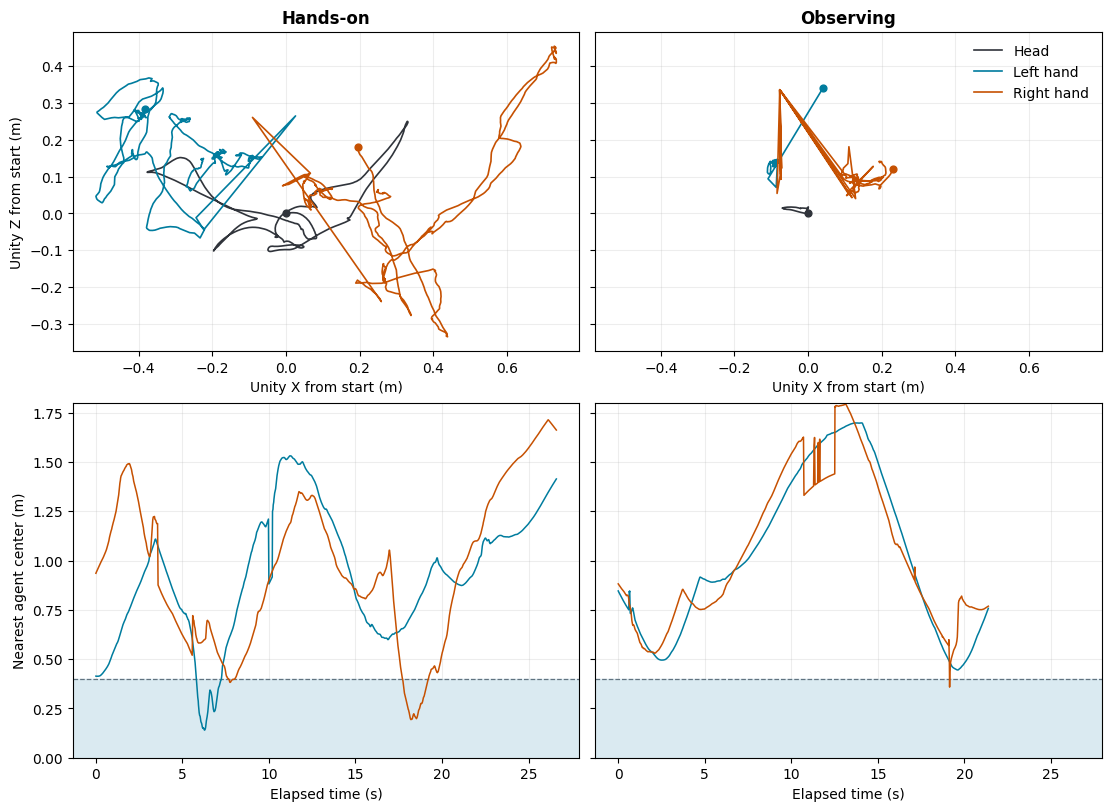

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained",
                         sharex="row", sharey="row")
for col, (label, body) in enumerate(runs.items()):
    paths, distances = axes[:, col]
    paths.set_title(label, fontweight="bold")
    origin = body[xyz("HeadPos")].iloc[0].to_numpy()
    for name, prefix in [("Head", "HeadPos"), ("Left hand", "LHandPos"), ("Right hand", "RHandPos")]:
        path = body[xyz(prefix)].to_numpy() - origin
        paths.plot(path[:, 0], path[:, 2], color=colors[name], label=name, linewidth=1.2)
        valid = np.flatnonzero(np.isfinite(path[:, 0]))
        if len(valid):
            x, _, z = path[valid[0]]
            paths.scatter(x, z, color=colors[name], s=24, zorder=3)
    paths.set_aspect("equal", adjustable="box")
    paths.set_xlabel("Unity X from start (m)")

    distances.axhspan(0, close_distance, color="#daeaf1")
    distances.axhline(close_distance, color="#617380", linestyle="--", linewidth=0.9)
    for side, name in hands.items():
        distances.plot(body["Time_s"], body[f"{side}Nearest_m"],
                       color=colors[name], linewidth=1.1)
    distances.set_ylim(bottom=0)
    distances.set_xlabel("Elapsed time (s)")
    for ax in (paths, distances):
        ax.set_axisbelow(True)
        ax.grid(alpha=0.22)

axes[0, 0].set_ylabel("Unity Z from start (m)")
axes[1, 0].set_ylabel("Nearest agent center (m)")
axes[0, 1].legend(loc="best", frameon=False)
plt.show()

## Summary

Hand speed is measured relative to the head using recorded time intervals. This removes shared head translation, though head turns can still contribute. The proximity percentage uses frames with a valid hand-to-agent distance.

In [3]:
rows = []
for label, body in runs.items():
    head = body[xyz("HeadPos")].to_numpy()
    dt = body["Time_s"].diff().to_numpy()
    for side, name in hands.items():
        relative = body[xyz(f"{side}HandPos")].to_numpy() - head
        displacement = np.linalg.norm(np.diff(relative, axis=0, prepend=np.nan), axis=1)
        speed = displacement[dt > 0] / dt[dt > 0]
        distance = body[f"{side}Nearest_m"].dropna()
        rows.append({
            "Session": label,
            "Hand": name,
            "Median hand speed relative to head (m/s)": np.nanmedian(speed),
            "Closest distance (m)": distance.min(),
            "Valid frames under 40 cm (%)": 100 * distance.lt(close_distance).mean(),
        })

pd.DataFrame(rows).set_index(["Session", "Hand"]).round(2)

Median hand speed relative to head (m/s)  \
Session   Hand                                                   
Hands-on  Left hand                                       0.14   
          Right hand                                      0.18   
Observing Left hand                                       0.02   
          Right hand                                      0.04   

                      Closest distance (m)  Valid frames under 40 cm (%)  
Session   Hand                                                            
Hands-on  Left hand                   0.14                          5.48  
          Right hand                  0.19                          7.13  
Observing Left hand                   0.45                          0.00  
          Right hand                  0.36                          0.09

The hands-on run shows a wider head path, quicker hand movement relative to the head, and repeated close approaches. In the observing run, the head stays near its starting position and the hands rarely get within 40 cm of an agent.

This comparison describes the two recordings. Proximity alone cannot tell us how much the hands caused the agents to change course, especially since the head also moved more in the hands-on run.